# RQ2 — Model comparison

Input: `../metrics/model_macro_f1.csv` (relative to this notebook; `results/rq2/metrics/model_macro_f1.csv` when run from the repository root).

Outputs (displayed inline; no files are written): descriptive statistics per model, normality and omnibus tests, Holm-corrected pairwise comparisons, a compact summary table, and a pairwise effect-size heatmap.

Run: *Run All*.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import pingouin as pg
from IPython.display import display


PROJECT_COLUMN = "project"

# Supports running the notebook either from results/rq2/analysis/
# or from the repository root.
DATA_PATH = Path("../metrics/model_macro_f1.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("results/rq2/metrics/model_macro_f1.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not find model_macro_f1.csv."
    )


# Load project-level Macro-F1 values.
df_raw = pd.read_csv(DATA_PATH)

if PROJECT_COLUMN not in df_raw.columns:
    raise ValueError(
        f"Required project column '{PROJECT_COLUMN}' was not found."
    )

if df_raw[PROJECT_COLUMN].duplicated().any():
    duplicates = (
        df_raw.loc[
            df_raw[PROJECT_COLUMN].duplicated(),
            PROJECT_COLUMN,
        ]
        .astype(str)
        .tolist()
    )

    raise ValueError(
        f"Duplicate project identifiers were found: {duplicates}"
    )

df_raw = df_raw.set_index(PROJECT_COLUMN)


# Every remaining column is expected to represent one model.
model_columns = df_raw.columns.tolist()

if len(model_columns) < 3:
    raise ValueError(
        "At least three model columns are required."
    )


# Validate that all model columns contain numeric Macro-F1 values.
for column in model_columns:
    numeric = pd.to_numeric(
        df_raw[column],
        errors="coerce",
    )

    observed = df_raw[column].notna()

    if observed.any() and not numeric.loc[observed].notna().all():
        raise ValueError(
            f"Model column '{column}' contains non-numeric values."
        )

    df_raw[column] = numeric


# Statistical comparisons require complete paired observations.
incomplete_mask = df_raw[model_columns].isna().any(axis=1)

removed_projects = (
    df_raw.index[incomplete_mask]
    .astype(str)
    .tolist()
)

df_clean = df_raw.loc[
    ~incomplete_mask,
    model_columns,
].copy()

if len(df_clean) < 3:
    raise ValueError(
        "Fewer than three complete paired projects remain."
    )


print(f"Data source: {DATA_PATH}")
print(f"Complete paired projects retained: {len(df_clean)}")
print(f"Detected models ({len(model_columns)}): {model_columns}")

if removed_projects:
    print(
        "Projects removed by complete-case paired filtering: "
        f"{removed_projects}"
    )

display(df_clean.head())

Data source: ..\metrics\model_macro_f1.csv
Complete paired projects retained: 30
Detected models (13): ['deepSeek r1 8b', 'gemma 3 27b', 'granite 3.3 8b', 'llama vision 3.2 11b', 'magistral 24b', 'mistral small 3.2 24b', 'phi-4 rp 14b', 'qwq 32b', 'aya expanse 32b', 'devstral 24b', 'gpt-oss 20b', 'qwen3 32b', 'qwen3 coder 30b']


,deepSeek r1 8b,gemma 3 27b,granite 3.3 8b,llama vision 3.2 11b,magistral 24b,mistral small 3.2 24b,phi-4 rp 14b,qwq 32b,aya expanse 32b,devstral 24b,gpt-oss 20b,qwen3 32b,qwen3 coder 30b
project,,,,,,,,,,,,,
cargo/clap,0.4528,0.4949,0.3543,0.3213,0.5081,0.5208,0.4235,0.6411,0.4337,0.6228,0.5653,0.4710,0.5692
go/google-cloud-go,0.3872,0.3557,0.2733,0.2528,0.4303,0.4003,0.2618,0.4943,0.3569,0.3893,0.4008,0.4165,0.3914
npm/angular,0.2772,0.2333,0.2586,0.1469,0.3165,0.2498,0.1880,0.3796,0.2373,0.2664,0.4259,0.3932,0.2850
npm/ant-design,0.2938,0.3013,0.2431,0.1775,0.3354,0.2979,0.3364,0.4105,0.2255,0.3372,0.4085,0.3556,0.2900
npm/biome,0.3423,0.3333,0.3344,0.2114,0.3861,0.4289,0.3689,0.4779,0.1985,0.4582,0.4662,0.4588,0.4159


## Analysis functions

In [2]:
from itertools import combinations
from scipy.stats import friedmanchisquare, shapiro, t, ttest_rel


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _effect_magnitude(effect, route):
    value = abs(float(effect))

    if route == "parametric":
        if value < 0.2:
            return "Negligible"
        if value < 0.5:
            return "Small"
        if value < 0.8:
            return "Medium"
        return "Large"

    if value < 0.1:
        return "Negligible"
    if value < 0.3:
        return "Small"
    if value < 0.5:
        return "Medium"
    return "Large"


def _sphericity_values(result):
    """Support named and tuple-like Pingouin return objects."""
    names = ("spher", "W", "chi2", "dof", "pval")
    if all(hasattr(result, name) for name in names):
        return {name: getattr(result, name) for name in names}

    return dict(zip(names, result))


def _pingouin_value(row, *candidates):
    normalized = {
        str(column).lower().replace("-", "_"): column
        for column in row.index
    }
    for candidate in candidates:
        key = candidate.lower().replace("-", "_")
        if key in normalized:
            return row[normalized[key]]
    raise KeyError(
        f"None of these columns were found: {candidates}"
    )


def _descriptive_table(data):
    n = len(data)
    means = data.mean()
    standard_deviations = data.std(ddof=1)
    standard_errors = standard_deviations / np.sqrt(n)
    critical_t = t.ppf(0.975, df=n - 1)
    mean_ranks = data.rank(
        axis=1,
        method="average",
        ascending=False,
    ).mean()

    table = pd.DataFrame({
        "N": n,
        "Mean Macro-F1": means,
        "SD": standard_deviations,
        "CI95 Lower": means - critical_t * standard_errors,
        "CI95 Upper": means + critical_t * standard_errors,
        "Mean Rank": mean_ranks,
    })

    return table.sort_values(
        ["Mean Rank", "Mean Macro-F1"],
        ascending=[True, False],
    )


def _pairwise_tests(data, route, alpha):
    rows = []

    for model_a, model_b in combinations(data.columns, 2):
        values_a = data[model_a].to_numpy()
        values_b = data[model_b].to_numpy()

        if route == "parametric":
            statistic, p_value = ttest_rel(values_a, values_b)

            if np.allclose(values_a - values_b, 0):
                effect = 0.0
            else:
                effect = pg.compute_effsize(
                    values_a,
                    values_b,
                    paired=True,
                    eftype="hedges",
                )

            statistic_name = "t"
            effect_name = "Hedges' g"
        else:
            if np.allclose(values_a - values_b, 0):
                statistic = 0.0
                p_value = 1.0
                effect = 0.0
            else:
                wilcoxon = pg.wilcoxon(
                    values_a,
                    values_b,
                    alternative="two-sided",
                ).iloc[0]
                statistic = _pingouin_value(
                    wilcoxon,
                    "W_val",
                    "W-val",
                )
                p_value = _pingouin_value(
                    wilcoxon,
                    "p_val",
                    "p-val",
                )
                effect = _pingouin_value(wilcoxon, "RBC")

            statistic_name = "W"
            effect_name = "Rank-biserial correlation"

        rows.append({
            "A": model_a,
            "B": model_b,
            "Mean A": float(np.mean(values_a)),
            "Mean B": float(np.mean(values_b)),
            "Statistic name": statistic_name,
            "Statistic": float(statistic),
            "p_raw": float(p_value),
            "Effect name": effect_name,
            "Effect": float(effect),
        })

    pairwise = pd.DataFrame(rows)
    reject, corrected_p = pg.multicomp(
        pairwise["p_raw"].to_numpy(),
        alpha=alpha,
        method="holm",
    )
    pairwise["p_Holm"] = corrected_p
    pairwise["Significant"] = reject
    pairwise["Winner"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["A"],
        pairwise["B"],
    )
    pairwise["Loser"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["B"],
        pairwise["A"],
    )
    pairwise["Absolute effect"] = pairwise["Effect"].abs()
    pairwise["Effect magnitude"] = pairwise["Effect"].map(
        lambda value: _effect_magnitude(value, route)
    )

    return pairwise


def _leader_pairwise_table(pairwise, leader):
    """Extract every comparison involving the descriptive leader.

    Effects are reoriented so that a positive "Effect vs. leader" means the
    effect favors the leader, regardless of whether the leader originally
    appeared in column A or B. Unlike `significant_pairwise`, this table is
    not filtered by significance: every other model is included, with a
    "Significant" column flagging which comparisons crossed alpha after
    Holm correction.
    """
    if pairwise is None:
        return None

    rows = []
    for _, row in pairwise.iterrows():
        if row["A"] != leader and row["B"] != leader:
            continue

        leader_is_a = row["A"] == leader
        if leader_is_a:
            other = row["B"]
            mean_leader = row["Mean A"]
            mean_other = row["Mean B"]
            effect_vs_leader = row["Effect"]
        else:
            other = row["A"]
            mean_leader = row["Mean B"]
            mean_other = row["Mean A"]
            effect_vs_leader = -row["Effect"]

        rows.append({
            "Leader": leader,
            "Other model": other,
            "Mean leader": float(mean_leader),
            "Mean other": float(mean_other),
            "Statistic name": row["Statistic name"],
            "Statistic": float(row["Statistic"]),
            "p_raw": float(row["p_raw"]),
            "p_Holm": float(row["p_Holm"]),
            "Effect name": row["Effect name"],
            "Effect vs. leader": float(effect_vs_leader),
            "Absolute effect": abs(float(effect_vs_leader)),
            "Effect magnitude": row["Effect magnitude"],
            "Significant": bool(row["Significant"]),
        })

    result = pd.DataFrame(rows)
    if result.empty:
        return result

    # Non-significant competitors first; within each group, better means first.
    return result.sort_values(
        ["Significant", "Mean other"],
        ascending=[True, False],
    ).reset_index(drop=True)


def run_model_comparison(data, alpha=0.05):
    descriptive = _descriptive_table(data)

    shapiro_rows = []
    for model in data.columns:
        statistic, p_value = shapiro(data[model])
        shapiro_rows.append({
            "Model": model,
            "N": int(data[model].notna().sum()),
            "W": float(statistic),
            "p": float(p_value),
            "Normality not rejected": bool(p_value >= alpha),
        })

    shapiro_results = pd.DataFrame(shapiro_rows).set_index("Model")
    all_normal = bool(
        shapiro_results["Normality not rejected"].all()
    )
    route = "parametric" if all_normal else "non-parametric"

    n_projects = len(data)
    n_models = len(data.columns)
    sphericity = None

    if route == "parametric":
        long_data = (
            data.rename_axis("Project")
            .reset_index()
            .melt(
                id_vars="Project",
                var_name="Model",
                value_name="Macro-F1",
            )
        )

        sphericity = _sphericity_values(
            pg.sphericity(
                data=long_data,
                dv="Macro-F1",
                within="Model",
                subject="Project",
            )
        )

        anova = pg.rm_anova(
            data=long_data,
            dv="Macro-F1",
            within="Model",
            subject="Project",
            correction=True,
            detailed=True,
            effsize="ng2",
        )
        anova_row = anova.iloc[0]
        statistic = float(_pingouin_value(anova_row, "F"))
        p_uncorrected = float(
            _pingouin_value(anova_row, "p_unc", "p-unc")
        )
        epsilon = float(_pingouin_value(anova_row, "eps"))
        effect = float(_pingouin_value(anova_row, "ng2"))

        if float(sphericity["pval"]) < alpha:
            p_value = float(
                _pingouin_value(
                    anova_row,
                    "p_GG_corr",
                    "p-GG-corr",
                )
            )
            df1 = epsilon * (n_models - 1)
            df2 = epsilon * (n_models - 1) * (n_projects - 1)
            correction = "Greenhouse-Geisser"
        else:
            p_value = p_uncorrected
            df1 = n_models - 1
            df2 = (n_models - 1) * (n_projects - 1)
            correction = "None"

        omnibus = {
            "test": "Repeated-measures ANOVA",
            "statistic name": "F",
            "statistic": statistic,
            "df1": float(df1),
            "df2": float(df2),
            "p": p_value,
            "effect name": "eta_G_squared",
            "effect": effect,
            "epsilon": epsilon,
            "correction": correction,
            "significant": bool(p_value < alpha),
        }
    else:
        statistic, p_value = friedmanchisquare(
            *[data[column].to_numpy() for column in data.columns]
        )
        kendalls_w = statistic / (
            n_projects * (n_models - 1)
        )
        omnibus = {
            "test": "Friedman",
            "statistic name": "chi-square",
            "statistic": float(statistic),
            "df1": float(n_models - 1),
            "df2": np.nan,
            "p": float(p_value),
            "effect name": "Kendall's W",
            "effect": float(kendalls_w),
            "epsilon": np.nan,
            "correction": "Not applicable",
            "significant": bool(p_value < alpha),
        }

    if omnibus["significant"]:
        pairwise = _pairwise_tests(data, route, alpha)
        significant_pairwise = pairwise.loc[
            pairwise["Significant"]
        ].copy()
    else:
        pairwise = None
        significant_pairwise = None

    leader = descriptive.index[0]

    leader_pairwise = (
        _leader_pairwise_table(pairwise, leader)
        if pairwise is not None
        else None
    )

    not_distinguishable = [leader]

    if pairwise is not None:
        for model in descriptive.index[1:]:
            comparison = pairwise.loc[
                (
                    (pairwise["A"] == leader)
                    & (pairwise["B"] == model)
                )
                | (
                    (pairwise["A"] == model)
                    & (pairwise["B"] == leader)
                )
            ]
            if len(comparison) != 1:
                raise ValueError(
                    "Missing or duplicated leader comparison for "
                    f"{model}."
                )
            if not bool(comparison.iloc[0]["Significant"]):
                not_distinguishable.append(model)

    summary = descriptive.copy()
    summary["Not distinguishable from leader"] = [
        model in not_distinguishable
        for model in summary.index
    ]

    print("DESCRIPTIVE MODEL TABLE")
    display(summary.round({
        "Mean Macro-F1": 4,
        "SD": 4,
        "CI95 Lower": 4,
        "CI95 Upper": 4,
        "Mean Rank": 2,
    }))

    print("SHAPIRO-WILK TESTS")
    shapiro_display = shapiro_results.copy()
    shapiro_display["W"] = shapiro_display["W"].round(4)
    shapiro_display["p"] = shapiro_display["p"].map(
        _format_p_plain
    )
    display(shapiro_display)

    print(f"SELECTED ROUTE: {route}")
    display(pd.DataFrame([omnibus]))

    if pairwise is None:
        print(
            "The omnibus test was not significant; confirmatory "
            "post-hoc comparisons were not performed."
        )
    else:
        print(
            "SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS "
            f"({len(significant_pairwise)} of {len(pairwise)})"
        )
        pairwise_display = significant_pairwise.copy()
        pairwise_display["p_raw"] = pairwise_display["p_raw"].map(
            _format_p_plain
        )
        pairwise_display["p_Holm"] = pairwise_display[
            "p_Holm"
        ].map(_format_p_plain)
        display(pairwise_display.round({
            "Mean A": 4,
            "Mean B": 4,
            "Statistic": 4,
            "Effect": 4,
        }))

        print(
            "ALL PAIRWISE COMPARISONS AGAINST THE DESCRIPTIVE LEADER "
            f"({len(leader_pairwise)} total)"
        )
        leader_display = leader_pairwise.copy()
        leader_display["p_raw"] = leader_display["p_raw"].map(
            _format_p_plain
        )
        leader_display["p_Holm"] = leader_display["p_Holm"].map(
            _format_p_plain
        )
        display(leader_display.round({
            "Mean leader": 4,
            "Mean other": 4,
            "Statistic": 4,
            "Effect vs. leader": 4,
            "Absolute effect": 4,
        }))

    return {
        "data": data,
        "descriptive": descriptive,
        "summary": summary,
        "shapiro": shapiro_results,
        "route": route,
        "sphericity": sphericity,
        "omnibus": omnibus,
        "pairwise": pairwise,
        "significant_pairwise": significant_pairwise,
        "leader_pairwise": leader_pairwise,
        "leader": leader,
        "not_distinguishable": not_distinguishable,
        "alpha": alpha,
    }


## Run the analysis

In [3]:
rq2_analysis = run_model_comparison(df_clean)

if rq2_analysis["sphericity"] is not None:
    print("MAUCHLY'S TEST OF SPHERICITY")
    display(pd.DataFrame([{
        "Mauchly W": rq2_analysis["sphericity"]["W"],
        "chi-square": rq2_analysis["sphericity"]["chi2"],
        "df": rq2_analysis["sphericity"]["dof"],
        "p": rq2_analysis["sphericity"]["pval"],
    }]).round(4))


DESCRIPTIVE MODEL TABLE


,N,Mean Macro-F1,SD,CI95 Lower,CI95 Upper,Mean Rank,Not distinguishable from leader
gpt-oss 20b,30,0.4676,0.0972,0.4313,0.5039,2.50,True
qwq 32b,30,0.4743,0.0989,0.4374,0.5112,2.58,True
qwen3 32b,30,0.4199,0.0842,0.3884,0.4513,4.47,False
qwen3 coder 30b,30,0.4008,0.0914,0.3667,0.4350,5.50,False
magistral 24b,30,0.4094,0.1087,0.3688,0.4500,5.67,False
devstral 24b,30,0.4065,0.1141,0.3639,0.4491,5.67,False
mistral small 3.2 24b,30,0.4065,0.0881,0.3736,0.4394,5.70,False
gemma 3 27b,30,0.3660,0.0840,0.3346,0.3974,7.58,False
deepSeek r1 8b,30,0.3505,0.0651,0.3262,0.3748,8.40,False
phi-4 rp 14b,30,0.3290,0.0922,0.2945,0.3634,9.73,False


SHAPIRO-WILK TESTS


,N,W,p,Normality not rejected
Model,,,,
deepSeek r1 8b,30,0.9676,.4759,True
gemma 3 27b,30,0.9806,.8418,True
granite 3.3 8b,30,0.9755,.6985,True
llama vision 3.2 11b,30,0.9219,.0300,False
magistral 24b,30,0.9356,.0693,True
mistral small 3.2 24b,30,0.9766,.7296,True
phi-4 rp 14b,30,0.9550,.2301,True
qwq 32b,30,0.9690,.5120,True
aya expanse 32b,30,0.9455,.1279,True


SELECTED ROUTE: non-parametric


,test,statistic name,statistic,df1,df2,p,effect name,effect,epsilon,correction,significant
0,Friedman,chi-square,229.215496,12.0,NaN,2.901159e-42,Kendall's W,0.63671,NaN,Not applicable,True


SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS (58 of 78)


,A,B,Mean A,Mean B,Statistic name,Statistic,p_raw,Effect name,Effect,p_Holm,Significant,Winner,Loser,Absolute effect,Effect magnitude
1,deepSeek r1 8b,granite 3.3 8b,0.3505,0.3076,W,81.0,.0012,Rank-biserial correlation,0.6516,.0271,True,deepSeek r1 8b,granite 3.3 8b,0.651613,Large
2,deepSeek r1 8b,llama vision 3.2 11b,0.3505,0.2504,W,0.0,<.001,Rank-biserial correlation,1.0000,<.001,True,deepSeek r1 8b,llama vision 3.2 11b,1.000000,Large
3,deepSeek r1 8b,magistral 24b,0.3505,0.4094,W,53.0,<.001,Rank-biserial correlation,-0.7720,.0067,True,magistral 24b,deepSeek r1 8b,0.772043,Large
4,deepSeek r1 8b,mistral small 3.2 24b,0.3505,0.4065,W,26.0,<.001,Rank-biserial correlation,-0.8882,<.001,True,mistral small 3.2 24b,deepSeek r1 8b,0.888172,Large
6,deepSeek r1 8b,qwq 32b,0.3505,0.4743,W,0.0,<.001,Rank-biserial correlation,-1.0000,<.001,True,qwq 32b,deepSeek r1 8b,1.000000,Large
8,deepSeek r1 8b,devstral 24b,0.3505,0.4065,W,71.0,<.001,Rank-biserial correlation,-0.6946,.0126,True,devstral 24b,deepSeek r1 8b,0.694624,Large
9,deepSeek r1 8b,gpt-oss 20b,0.3505,0.4676,W,11.0,<.001,Rank-biserial correlation,-0.9527,<.001,True,gpt-oss 20b,deepSeek r1 8b,0.952688,Large
10,deepSeek r1 8b,qwen3 32b,0.3505,0.4199,W,22.0,<.001,Rank-biserial correlation,-0.9054,<.001,True,qwen3 32b,deepSeek r1 8b,0.905376,Large
11,deepSeek r1 8b,qwen3 coder 30b,0.3505,0.4008,W,54.0,<.001,Rank-biserial correlation,-0.7677,.0028,True,qwen3 coder 30b,deepSeek r1 8b,0.767742,Large
12,gemma 3 27b,granite 3.3 8b,0.3660,0.3076,W,45.0,<.001,Rank-biserial correlation,0.8065,.0011,True,gemma 3 27b,granite 3.3 8b,0.806452,Large


ALL PAIRWISE COMPARISONS AGAINST THE DESCRIPTIVE LEADER (12 total)


,Leader,Other model,Mean leader,Mean other,Statistic name,Statistic,p_raw,p_Holm,Effect name,Effect vs. leader,Absolute effect,Effect magnitude,Significant
0,gpt-oss 20b,qwq 32b,0.4676,0.4743,W,204.5,.5716,1.0000,Rank-biserial correlation,-0.1204,0.1204,Small,False
1,gpt-oss 20b,qwen3 32b,0.4676,0.4199,W,69.0,<.001,.0113,Rank-biserial correlation,0.7032,0.7032,Large,True
2,gpt-oss 20b,magistral 24b,0.4676,0.4094,W,67.0,<.001,.0097,Rank-biserial correlation,0.7118,0.7118,Large,True
3,gpt-oss 20b,mistral small 3.2 24b,0.4676,0.4065,W,56.0,<.001,.0034,Rank-biserial correlation,0.7591,0.7591,Large,True
4,gpt-oss 20b,devstral 24b,0.4676,0.4065,W,56.0,<.001,.0034,Rank-biserial correlation,0.7591,0.7591,Large,True
5,gpt-oss 20b,qwen3 coder 30b,0.4676,0.4008,W,28.0,<.001,<.001,Rank-biserial correlation,0.8796,0.8796,Large,True
6,gpt-oss 20b,gemma 3 27b,0.4676,0.3660,W,2.0,<.001,<.001,Rank-biserial correlation,0.9914,0.9914,Large,True
7,gpt-oss 20b,deepSeek r1 8b,0.4676,0.3505,W,11.0,<.001,<.001,Rank-biserial correlation,0.9527,0.9527,Large,True
8,gpt-oss 20b,phi-4 rp 14b,0.4676,0.3290,W,0.0,<.001,<.001,Rank-biserial correlation,1.0000,1.0000,Large,True
9,gpt-oss 20b,aya expanse 32b,0.4676,0.3139,W,0.0,<.001,<.001,Rank-biserial correlation,1.0000,1.0000,Large,True


## Compact table

In [4]:
compact_table = rq2_analysis["summary"][[
    "Mean Macro-F1",
    "SD",
    "Mean Rank",
    "Not distinguishable from leader",
]].copy()

display(compact_table.round({
    "Mean Macro-F1": 3,
    "SD": 3,
    "Mean Rank": 2,
}))

,Mean Macro-F1,SD,Mean Rank,Not distinguishable from leader
gpt-oss 20b,0.468,0.097,2.50,True
qwq 32b,0.474,0.099,2.58,True
qwen3 32b,0.420,0.084,4.47,False
qwen3 coder 30b,0.401,0.091,5.50,False
magistral 24b,0.409,0.109,5.67,False
devstral 24b,0.406,0.114,5.67,False
mistral small 3.2 24b,0.407,0.088,5.70,False
gemma 3 27b,0.366,0.084,7.58,False
deepSeek r1 8b,0.350,0.065,8.40,False
phi-4 rp 14b,0.329,0.092,9.73,False


## Holm-corrected pairwise effect-size heatmap

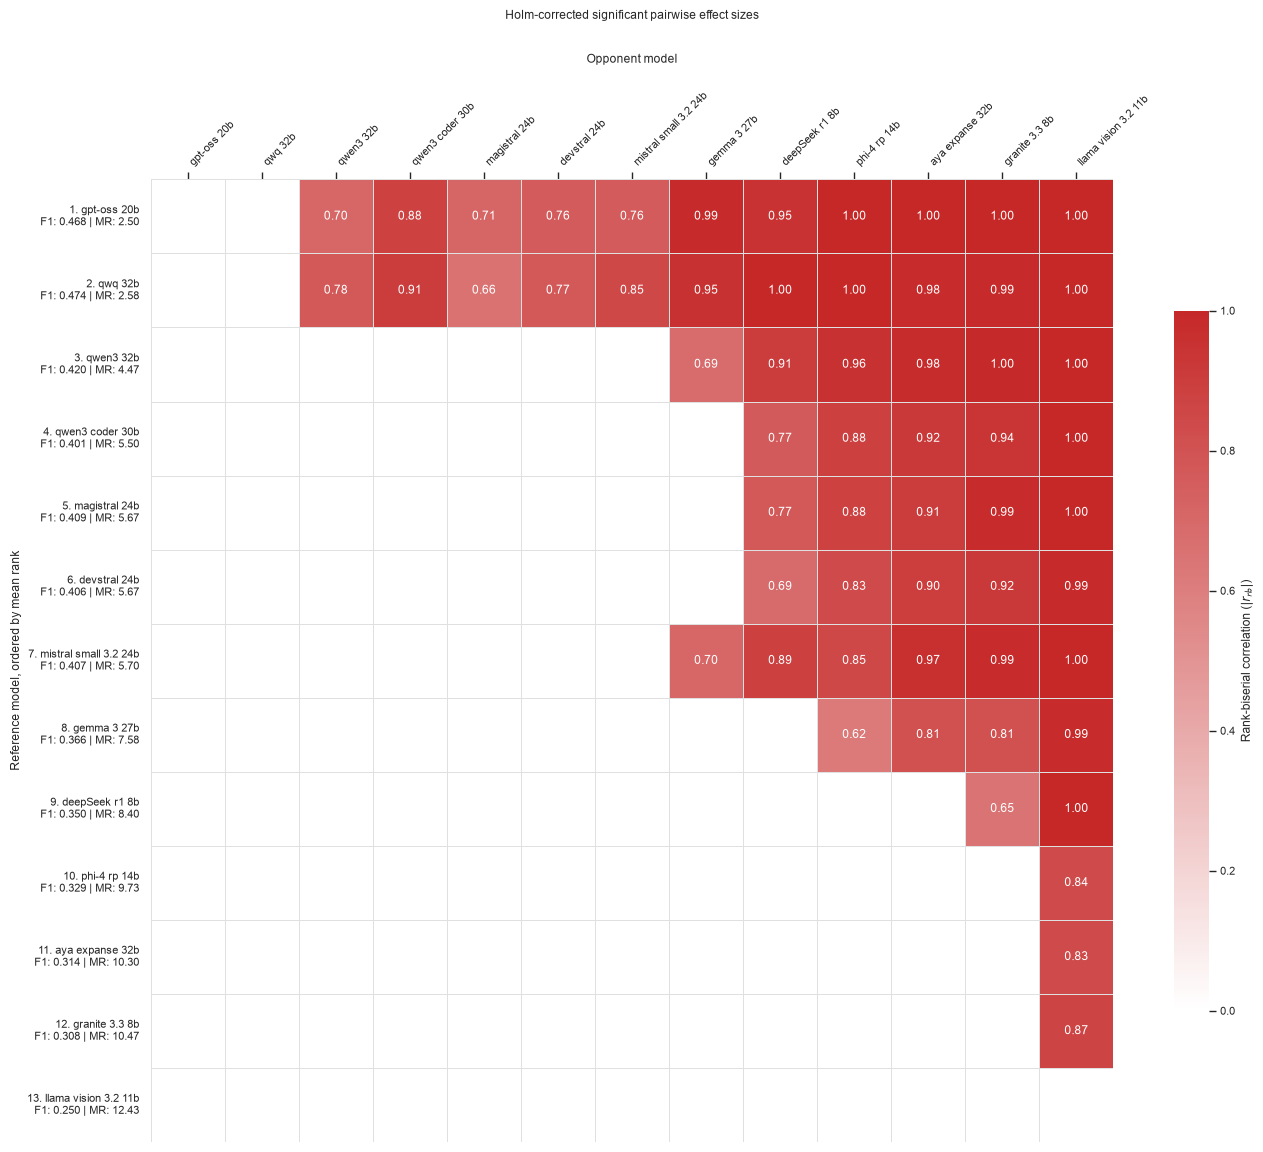

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

pairwise = rq2_analysis["pairwise"]

if pairwise is None:
    print(
        "Heatmap not generated because confirmatory post-hoc tests "
        "were not warranted."
    )
else:
    ordered_models = rq2_analysis["descriptive"].index.tolist()
    effect_matrix = pd.DataFrame(
        np.nan,
        index=ordered_models,
        columns=ordered_models,
    )
    p_matrix = effect_matrix.copy()

    for _, row in pairwise.iterrows():
        model_a = row["A"]
        model_b = row["B"]
        effect = row["Effect"]
        p_value = row["p_Holm"]

        effect_matrix.loc[model_a, model_b] = effect
        effect_matrix.loc[model_b, model_a] = -effect
        p_matrix.loc[model_a, model_b] = p_value
        p_matrix.loc[model_b, model_a] = p_value

    display_matrix = effect_matrix.copy()
    annotations = pd.DataFrame(
        "",
        index=ordered_models,
        columns=ordered_models,
    )

    for row_index in range(len(ordered_models)):
        for column_index in range(len(ordered_models)):
            p_value = p_matrix.iloc[row_index, column_index]
            value = effect_matrix.iloc[row_index, column_index]

            if (
                column_index > row_index
                and pd.notna(p_value)
                and p_value < rq2_analysis["alpha"]
            ):
                annotations.iloc[
                    row_index,
                    column_index,
                ] = f"{value:.2f}"
            else:
                display_matrix.iloc[
                    row_index,
                    column_index,
                ] = np.nan

    diagonal_and_lower = np.tril(
        np.ones(display_matrix.shape, dtype=bool),
        k=0,
    )

    row_labels = []
    for position, model in enumerate(ordered_models, start=1):
        row = rq2_analysis["descriptive"].loc[model]
        row_labels.append(
            f"{position}. {model}\n"
            f"F1: {row['Mean Macro-F1']:.3f} | "
            f"MR: {row['Mean Rank']:.2f}"
        )

    sns.set_theme(style="white", context="paper", font_scale=0.9)
    figure_size = max(11, 0.9 * len(ordered_models))
    fig, ax = plt.subplots(
        figsize=(figure_size + 2, figure_size),
    )

    color_map = LinearSegmentedColormap.from_list("white_red", ["#ffffff", "#c62828"])
    effect_label = (
        "|Hedges' g|"
        if rq2_analysis["route"] == "parametric"
        else r"Rank-biserial correlation ($|r_{rb}|$)"
    )
    effect_limit = (
        max(1.0, float(pairwise["Absolute effect"].max()))
        if rq2_analysis["route"] == "parametric"
        else 1.0
    )

    sns.heatmap(
        display_matrix.abs(),
        annot=annotations,
        fmt="",
        mask=diagonal_and_lower,
        cmap=color_map,
        vmin=0,
        vmax=effect_limit,
        square=True,
        linewidths=0.6,
        linecolor="#e0e0e0",
        cbar_kws={"label": effect_label, "shrink": 0.7},
        ax=ax,
    )

    ax.set_xticklabels(
        ordered_models,
        rotation=45,
        ha="left",
    )
    ax.set_yticklabels(row_labels, rotation=0)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("Opponent model", labelpad=20)
    ax.set_ylabel("Reference model, ordered by mean rank")
    ax.set_title(
        "Holm-corrected significant pairwise effect sizes",
        pad=25,
    )

    fig.tight_layout()
    # fig.savefig(
    #     "rq2_pairwise_effect_sizes.png",
    #     dpi=200,
    #     bbox_inches="tight",
    # )
    plt.show()
